In [ ]:
Add code to recharge_theme.py

In [3]:

import numpy as np
import pandas as pd

np.random.seed(42)

# Generate 300 prepaid users
user_id = np.arange(1, 301)

circle = np.random.choice(
    ["Gujarat", "Maharashtra", "Rajasthan"],
    size=300
)

plan = np.random.choice(
    ["Rs199", "Rs299", "Rs599"],
    size=300,
    p=[0.5, 0.3, 0.2]
)

means = np.where(
    plan == "Rs199", 18,
    np.where(plan == "Rs299", 32, 60)
)

data_gb_used = np.round(
    np.maximum(
        np.random.normal(means, means * 0.25),
        1
    ),
    1
)

calls_min = np.round(
    np.maximum(
        np.random.normal(420, 120, 300),
        30
    )
).astype(int)

df = pd.DataFrame({
    "user_id": user_id,
    "circle": circle,
    "plan": plan,
    "data_gb_used": data_gb_used,
    "calls_min": calls_min
})

# Save CSV
df.to_csv("recharge_usage.csv", index=False)

print(df.head())
print("Total Users:", len(df))
print("CSV created successfully!")


   user_id     circle   plan  data_gb_used  calls_min
0        1  Rajasthan  Rs199          12.5        523
1        2    Gujarat  Rs599          62.8        495
2        3  Rajasthan  Rs199          24.3        422
3        4  Rajasthan  Rs199          16.0        427
4        5    Gujarat  Rs199          19.5        217
Total Users: 300
CSV created successfully!


In [5]:
df = pd.read_csv("recharge_usage.csv")

print(df.head())
print("Total Users:", len(df))
print("Data loaded successfully!")

   user_id     circle   plan  data_gb_used  calls_min
0        1  Rajasthan  Rs199          12.5        523
1        2    Gujarat  Rs599          62.8        495
2        3  Rajasthan  Rs199          24.3        422
3        4  Rajasthan  Rs199          16.0        427
4        5    Gujarat  Rs199          19.5        217
Total Users: 300
Data loaded successfully!


In [4]:
df = pd.read_csv("recharge_usage.csv")

print(df.head())
print("Total Users:", len(df))
print("Data loaded successfully!")

   user_id     circle   plan  data_gb_used  calls_min
0        1  Rajasthan  Rs199          12.5        523
1        2    Gujarat  Rs599          62.8        495
2        3  Rajasthan  Rs199          24.3        422
3        4  Rajasthan  Rs199          16.0        427
4        5    Gujarat  Rs199          19.5        217
Total Users: 300
Data loaded successfully!


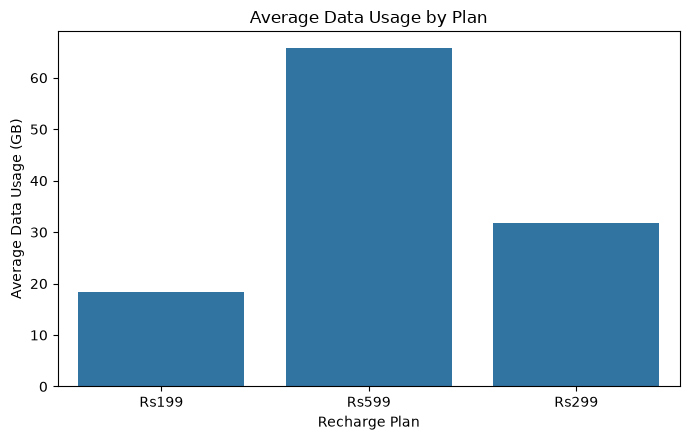

Barplot created successfully!


In [6]:

import seaborn as sns
import matplotlib.pyplot as plt

# Chart 1: Average Data Usage by Plan
fig_bar, ax_bar = plt.subplots(figsize=(7, 4.5))

sns.barplot(
    data=df,
    x="plan",
    y="data_gb_used",
    estimator="mean",
    errorbar=None,
    ax=ax_bar
)

ax_bar.set_title("Average Data Usage by Plan")
ax_bar.set_xlabel("Recharge Plan")
ax_bar.set_ylabel("Average Data Usage (GB)")

fig_bar.tight_layout()

plt.show()

print("Barplot created successfully!")


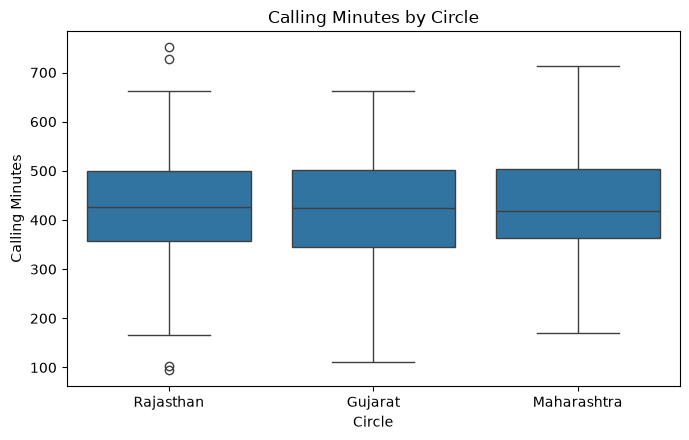

Boxplot created successfully!


In [7]:

# Chart 2: Boxplot

fig_box, ax_box = plt.subplots(figsize=(7, 4.5))

sns.boxplot(
    data=df,
    x="circle",
    y="calls_min",
    ax=ax_box
)

ax_box.set_title("Calling Minutes by Circle")
ax_box.set_xlabel("Circle")
ax_box.set_ylabel("Calling Minutes")

fig_box.tight_layout()

plt.show()

print("Boxplot created successfully!")


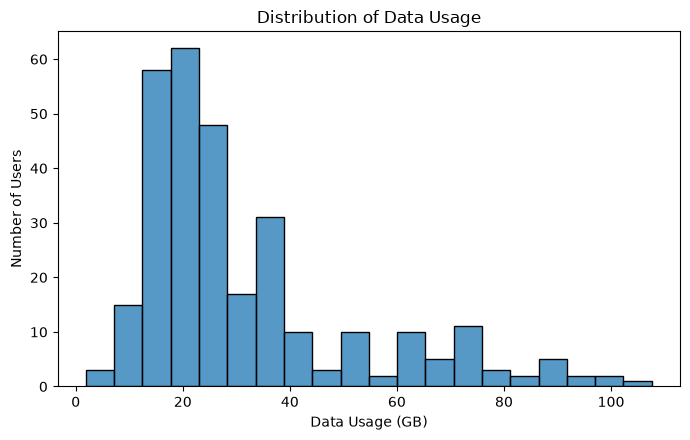

Histogram created successfully!
Task 1 Completed!


In [8]:

# Chart 3: Histogram

fig_hist, ax_hist = plt.subplots(figsize=(7, 4.5))

sns.histplot(
    data=df,
    x="data_gb_used",
    bins=20,
    ax=ax_hist
)

ax_hist.set_title("Distribution of Data Usage")
ax_hist.set_xlabel("Data Usage (GB)")
ax_hist.set_ylabel("Number of Users")

fig_hist.tight_layout()

plt.show()

print("Histogram created successfully!")
print("Task 1 Completed!")


In [9]:

import os
from PIL import Image

# Export barplot at different DPI
for dpi in [100, 300, 600]:

    filename = f"bar_{dpi}.png"

    fig_bar.savefig(
        filename,
        dpi=dpi,
        bbox_inches="tight"
    )

    # Get file size in KB
    size_kb = os.path.getsize(filename) / 1024

    # Get image width in pixels
    with Image.open(filename) as img:
        width = img.size[0]

    print(
        f"{filename} | "
        f"Size: {size_kb:.2f} KB | "
        f"Width: {width} pixels"
    )

print("\nTask 2 Completed Successfully!")


bar_100.png | Size: 16.48 KB | Width: 690 pixels
bar_300.png | Size: 64.37 KB | Width: 2069 pixels
bar_600.png | Size: 152.28 KB | Width: 4135 pixels

Task 2 Completed Successfully!


In [10]:

import matplotlib.pyplot as plt
import os

# Keep SVG text as text
plt.rcParams["svg.fonttype"] = "none"

# Export histogram as SVG
fig_hist.savefig(
    "recharge_hist.svg",
    format="svg",
    bbox_inches="tight"
)

# Export boxplot as PDF
fig_box.savefig(
    "recharge_box.pdf",
    format="pdf",
    bbox_inches="tight"
)

print("Histogram saved as SVG!")
print("Boxplot saved as PDF!")

print("\nTask 3 Completed Successfully!")


Histogram saved as SVG!
Boxplot saved as PDF!

Task 3 Completed Successfully!


In [12]:

import os

def export_chart(fig, name):

    # Create report_visuals folder
    folder = "report_visuals"
    os.makedirs(folder, exist_ok=True)

    # File paths
    png_path = os.path.join(folder, f"{name}.png")
    svg_path = os.path.join(folder, f"{name}.svg")

    # Save PNG at 300 DPI
    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight"
    )

    # Save SVG
    fig.savefig(
        svg_path,
        format="svg",
        bbox_inches="tight"
    )

    return png_path, svg_path


In [14]:

import os

def apply_corporate_theme():
    import seaborn as sns
    import matplotlib.pyplot as plt

    sns.set_theme(style="whitegrid", palette="deep")
    plt.rcParams["figure.dpi"] = 100


def export_chart(fig, name):
    folder = "report_visuals"
    os.makedirs(folder, exist_ok=True)

    png_path = os.path.join(folder, f"{name}.png")
    svg_path = os.path.join(folder, f"{name}.svg")

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        svg_path,
        format="svg",
        bbox_inches="tight"
    )

    return png_path, svg_path


In [16]:

import os

print("Current Folder:", os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

print("\nTheme file exists:",
      os.path.isfile("recharge_theme.py"))


Current Folder: d:\sql+power bi\assmt\recharge_export.ipynb

Files in this folder:
['bar_100.png', 'bar_300.png', 'bar_600.png', 'recharge_box.pdf', 'recharge_hist.svg', 'recharge_usage.csv', 'Untitled-1.ipynb', 'Untitled-2.ipynb']

Theme file exists: False


In [17]:

from pathlib import Path

theme_file = Path("recharge_theme.py")

if not theme_file.exists():
    theme_file.write_text("""
import os
import seaborn as sns
import matplotlib.pyplot as plt

def apply_corporate_theme():
    sns.set_theme(style="whitegrid", palette="deep")

def export_chart(fig, name):
    os.makedirs("report_visuals", exist_ok=True)

    png_path = f"report_visuals/{name}.png"
    svg_path = f"report_visuals/{name}.svg"

    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    fig.savefig(svg_path, format="svg", bbox_inches="tight")

    return png_path, svg_path
""", encoding="utf-8")
    print("recharge_theme.py created!")
else:
    print("recharge_theme.py already exists.")

print("File location:", theme_file.resolve())


recharge_theme.py created!
File location: D:\sql+power bi\assmt\recharge_export.ipynb\recharge_theme.py


In [18]:

import importlib
importlib.invalidate_caches()

from recharge_theme import export_chart

print("Module imported successfully!")


Module imported successfully!


In [19]:

from recharge_theme import export_chart
import os

# Export all three charts
exported_files = []

charts = [
    ("bar", fig_bar),
    ("box", fig_box),
    ("hist", fig_hist)
]

for name, fig in charts:

    png_path, svg_path = export_chart(fig, name)

    exported_files.append(png_path)
    exported_files.append(svg_path)

    print("Saved:", png_path)
    print("Saved:", svg_path)

print("\nTotal Files:", len(exported_files))

# Verify all six files exist
assert len(exported_files) == 6
assert all(os.path.isfile(f) for f in exported_files)

print("\nAll 6 charts exported successfully!")


Saved: report_visuals/bar.png
Saved: report_visuals/bar.svg
Saved: report_visuals/box.png
Saved: report_visuals/box.svg
Saved: report_visuals/hist.png
Saved: report_visuals/hist.svg

Total Files: 6

All 6 charts exported successfully!


In [20]:

import os
import pandas as pd

# Create export summary
summary_data = []

for file in exported_files:

    summary_data.append({
        "file_name": os.path.basename(file),
        "format": os.path.splitext(file)[1][1:].upper(),
        "size_kb": round(os.path.getsize(file) / 1024, 2)
    })

# Convert to DataFrame
export_summary = pd.DataFrame(summary_data)

# Save CSV
export_summary.to_csv(
    "export_summary.csv",
    index=False
)

# Display summary
print("EXPORT SUMMARY")
print(export_summary.to_string(index=False))

print("\nTotal Files:", len(export_summary))
print("export_summary.csv created successfully!")


EXPORT SUMMARY
file_name format  size_kb
  bar.png    PNG    64.37
  bar.svg    SVG     9.56
  box.png    PNG    58.83
  box.svg    SVG    13.42
 hist.png    PNG    58.67
 hist.svg    SVG    15.89

Total Files: 6
export_summary.csv created successfully!


In [21]:

from pathlib import Path
import pandas as pd

required_files = [
    "recharge_theme.py",
    "recharge_usage.csv",
    "bar_100.png",
    "bar_300.png",
    "bar_600.png",
    "recharge_hist.svg",
    "recharge_box.pdf",
    "export_summary.csv",
    "report_visuals/bar.png",
    "report_visuals/bar.svg",
    "report_visuals/box.png",
    "report_visuals/box.svg",
    "report_visuals/hist.png",
    "report_visuals/hist.svg"
]

missing = [f for f in required_files if not Path(f).is_file()]

summary = pd.read_csv("export_summary.csv")

assert not missing, f"Missing files: {missing}"
assert len(summary) == 6, "Summary must contain 6 rows"
assert set(summary.columns) == {
    "file_name", "format", "size_kb"
}

print("All required files found!")
print("Export summary verified!")
print("SESSION 11 VERIFIED SUCCESSFULLY!")


All required files found!
Export summary verified!
SESSION 11 VERIFIED SUCCESSFULLY!
